In [1]:
# ============================================================
# California Wildfire Insurance Loss Prediction
# ============================================================
# Inputs:
#   1. CA Insurance Data        (SB 824 ZIP-level)
#   2. CA Climate Data          (NCEI county temp + precip)
#   3. CA Drought Data          (DSCI weekly)
#   4. CA Fire Perimeter Data   (CAL FIRE shapefile)
#   5. CA Fire Structure Damage (DINS inspection records)
#   6. TIGER 2025 County Shapes (for spatial joins)
#
# Policy types included: HO, DT, DO, MH, RT, CO, FP
# FP = CA FAIR Plan (insurer of last resort, high-risk properties)
# Policy types excluded: none — all 7 residential types included
#
# Outputs (saved to Processed Data/):
#   master_baseline.csv  — insurance-only features (11 cols)
#   master_enhanced.csv  — all features (27 cols)
#   master_full.csv      — all columns including intermediates
#
# Train: Calendar Year 18-21 | Test: Calendar Year 22-23
# Note: 2017 data loaded internally for lag computation only
# ============================================================

In [2]:
import pandas as pd
import numpy as np
import geopandas as gpd
import glob, os, zipfile, warnings
warnings.filterwarnings("ignore")

# ── Paths ─────────────────────────────────────────────────────
# Set BASE to the folder that holds the raw data (see README)
BASE = "./Data"

INSURANCE_PATH = f"{BASE}/CA Insurance data/Residential-Property-Coverage-Amounts-Wildfire-Risk-and-Losses.csv"
CLIMATE_DIR    = f"{BASE}/CA Climate Data"
DROUGHT_PATH   = f"{BASE}/CA Droght Data/dm_export_20170102_20231231.csv"
FIRE_ZIP       = f"{BASE}/CA Fire Perimeter Data/California_Historic_Fire_Perimeters_-6273763535668926275.zip"
DINS_PATH      = f"{BASE}/CA Fire Structure Damage Data/POSTFIRE_MASTER_DATA_SHARE_795979837499149141.csv"
TIGER_ZIP      = f"{BASE}/TIGER Shapefiles/tl_2025_us_county.zip"

OUTPUT_DIR     = f"{BASE}/../Processed Data"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# CA Albers — meters, standard for CA spatial analysis
TARGET_CRS     = "EPSG:3310"

# Policy types to include
# FP = California FAIR Plan (insurer of last resort for high-risk properties)
#      Included: concentrated in fire-prone counties (Butte, El Dorado, Kern)
#      with consistent losses $7-13M/year — most relevant to wildfire risk
POLICY_TYPES   = ["HO", "DT", "DO", "MH", "RT", "CO", "FP"]

# Loss columns — all fire + smoke, catastrophe + non-catastrophe
LOSS_COLS = [
    "NonCat CovA Fire Losses",  "NonCat CovA Smoke Losses",
    "NonCat CovC Fire Losses",  "NonCat CovC Smoke Losses",
    "Cat CovA Fire Losses",     "Cat CovA Smoke Losses",
    "Cat CovC Fire Losses",     "Cat CovC Smoke Losses",
]

print("=" * 65)
print("CALIFORNIA WILDFIRE INSURANCE — PREPROCESSING PIPELINE")
print("=" * 65)
print(f"Policy types: {POLICY_TYPES}")
print(f"Output dir:   {OUTPUT_DIR}")

CALIFORNIA WILDFIRE INSURANCE — PREPROCESSING PIPELINE
Policy types: ['HO', 'DT', 'DO', 'MH', 'RT', 'CO', 'FP']
Output dir:   <PROJECT_ROOT>/Data/../Processed Data


In [3]:
# ============================================================
# STEP 0: LOAD FROM SAVED CSVs IF AVAILABLE
# ============================================================
# If processed CSVs already exist, load them directly and skip
# the heavy processing (spatial joins, file parsing etc.)
# To force reprocessing from raw files, set FORCE_REPROCESS = True
# ============================================================
import sys
FORCE_REPROCESS = False

baseline_path = f"{OUTPUT_DIR}/master_baseline.csv"
enhanced_path = f"{OUTPUT_DIR}/master_enhanced.csv"
full_path      = f"{OUTPUT_DIR}/master_full.csv"

all_exist = all(os.path.exists(p) for p in
                [baseline_path, enhanced_path, full_path])

if all_exist and not FORCE_REPROCESS:
    print("\n" + "=" * 65)
    print("STEP 0: Loading from saved CSVs")
    print("        (set FORCE_REPROCESS=True to rerun from raw files)")
    print("=" * 65)
    baseline_df = pd.read_csv(baseline_path)
    enhanced_df = pd.read_csv(enhanced_path)
    master_full = pd.read_csv(full_path)
    print(f"  \u2705 master_baseline.csv  \u2192  {baseline_df.shape}")
    print(f"  \u2705 master_enhanced.csv  \u2192  {enhanced_df.shape}")
    print(f"  \u2705 master_full.csv      \u2192  {master_full.shape}")
    print(f"\nTrain: {(baseline_df['Split']=='train').sum()} rows  "
          f"| Test: {(baseline_df['Split']=='test').sum()} rows")
    print(f"Counties: {baseline_df['County'].nunique()}  "
          f"| Years: {sorted(baseline_df['Cal_Year'].unique())}")
    print("\n\u2705 Ready for modeling — skipping preprocessing steps 1-10")

else:
    if FORCE_REPROCESS:
        print("\nSTEP 0: FORCE_REPROCESS=True — rerunning full pipeline")
    else:
        print("\nSTEP 0: Processed CSVs not found — running full pipeline")
    print("        (this will take 3-5 minutes due to spatial joins)\n")



STEP 0: Loading from saved CSVs
        (set FORCE_REPROCESS=True to rerun from raw files)
  ✅ master_baseline.csv  →  (348, 12)
  ✅ master_enhanced.csv  →  (348, 26)
  ✅ master_full.csv      →  (348, 33)

Train: 232 rows  | Test: 116 rows
Counties: 58  | Years: [np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]

✅ Ready for modeling — skipping preprocessing steps 1-10


In [4]:

# ============================================================
# STEP 1: INSURANCE DATA
# ============================================================
print("\n" + "=" * 65)
print("STEP 1: Load and aggregate insurance data")
print("=" * 65)

ins_raw = pd.read_csv(INSURANCE_PATH, low_memory=False)
print(f"Raw records: {len(ins_raw):,}")

#  Filter to "All Companies" source only 
# session which used: df = df[df["Source"] == "All Companies"].copy()
# This ensures we use the aggregated all-company view not individual insurers
print(f"Source values: {ins_raw['Source'].value_counts().to_dict()}")
ins_raw = ins_raw[ins_raw["Source"] == "All Companies"].copy()
print(f"After Source filter: {len(ins_raw):,} records")

print(f"Policy type counts:\n{ins_raw['Policy Type'].value_counts()}")

# Convert numeric columns
for col in LOSS_COLS + ["Earned Exp", "Earned Prem",
                         "Avg Cov A  ", "Avg Cov C  "]:
    ins_raw[col] = pd.to_numeric(ins_raw[col], errors="coerce").fillna(0)

ins_raw["Total_Wildfire_Loss"] = ins_raw[LOSS_COLS].sum(axis=1)

# Filter: valid policy types, years 2018-2023, valid county
# Excludes "z No County" — 804 records, $1.6M loss (<0.01% of total)
ins = ins_raw[
    (ins_raw["Policy Type"].isin(POLICY_TYPES)) &
    (ins_raw["Calendar Year"].between(18, 23)) &
    (ins_raw["County"].notna()) &
    (ins_raw["County"] != "z No County")
].copy()

no_county = ins_raw[ins_raw["County"] == "z No County"]
print(f"Excluded 'z No County': {len(no_county)} records, "
      f"${no_county['Total_Wildfire_Loss'].sum():,.0f} loss "
      f"(<0.01% of total)")

print(f"\nAfter filtering: {len(ins):,} records")
print(f"Loss by policy type:")
print(ins.groupby("Policy Type")["Total_Wildfire_Loss"]
      .sum().sort_values(ascending=False)
      .apply(lambda x: f"  ${x:,.0f}"))

# Aggregate ZIP → County-Year
county_ins = (ins.groupby(["County", "Calendar Year"])
              .agg(
                  Total_Wildfire_Loss=("Total_Wildfire_Loss", "sum"),
                  Earned_Exp         =("Earned Exp",          "sum"),
                  Earned_Prem        =("Earned Prem",         "sum"),
                  Avg_Cov_A          =("Avg Cov A  ",         "mean"),
                  Avg_Cov_C          =("Avg Cov C  ",         "mean"),
              )
              .reset_index()
              .rename(columns={"Calendar Year": "Cal_Year"}))

# Derived insurance features
county_ins["Log_Exposure"] = np.log(county_ins["Earned_Exp"].clip(lower=1))
county_ins["Pure_Premium"] = (county_ins["Total_Wildfire_Loss"] /
                               county_ins["Earned_Exp"].clip(lower=1))
county_ins["Loss_Ratio"]   = (county_ins["Total_Wildfire_Loss"] /
                               county_ins["Earned_Prem"].clip(lower=1))
county_ins["Year_4digit"]  = county_ins["Cal_Year"] + 2000

print(f"\nCounty-year records: {len(county_ins)}")
print(f"Counties: {county_ins['County'].nunique()}")
print(f"Years (Cal): {sorted(county_ins['Cal_Year'].unique())}")


STEP 1: Load and aggregate insurance data
Raw records: 197,290
Source values: {'All Companies': 71928, 'PPC Scores': 65997, 'Fire Risk Scores': 59365}
After Source filter: 71,928 records
Policy type counts:
Policy Type
RT    12136
HO    11319
DT    10924
DO    10393
FP     9934
MH     9376
CO     7846
Name: count, dtype: int64
Excluded 'z No County': 804 records, $1,607,826 loss (<0.01% of total)

After filtering: 71,124 records
Loss by policy type:
Policy Type
HO      $15,621,448,706
DT       $2,269,419,040
DO         $920,323,662
MH         $565,341,184
RT         $240,517,017
CO         $165,298,972
FP          $69,386,508
Name: Total_Wildfire_Loss, dtype: object

County-year records: 348
Counties: 58
Years (Cal): [np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]


In [5]:
# ============================================================
# STEP 2: CLIMATE DATA
# ============================================================
print("\n" + "=" * 65)
print("STEP 2: Load climate data (temperature + precipitation)")
print("=" * 65)

def load_climate_files(pattern, value_col):
    """Load NCEI county CSVs — skip 3-line metadata header."""
    dfs = []
    for f in sorted(glob.glob(pattern)):
        year = int(os.path.basename(f).split("_")[-1].replace(".csv", ""))
        df   = pd.read_csv(f, skiprows=3)
        df.columns = df.columns.str.strip()
        df   = df[["Name", "Value"]].copy()
        df.columns = ["County_Raw", value_col]
        df["Year_4digit"] = year
        df["County"] = (df["County_Raw"]
                        .str.replace(" County", "", regex=False)
                        .str.replace(", California", "", regex=False)
                        .str.strip())
        dfs.append(df[["County", "Year_4digit", value_col]])
    result = pd.concat(dfs, ignore_index=True)
    print(f"  {value_col}: {len(result)} records, "
          f"years {sorted(result['Year_4digit'].unique())}")
    return result

temp_df   = load_climate_files(
    f"{CLIMATE_DIR}/ncei_temp_data_*.csv",  "Avg_Temperature")
precip_df = load_climate_files(
    f"{CLIMATE_DIR}/ncei_precp_data_*.csv", "Avg_Precipitation")

climate_df = temp_df.merge(
    precip_df, on=["County", "Year_4digit"], how="outer")
print(f"Combined climate records: {len(climate_df)}")



STEP 2: Load climate data (temperature + precipitation)
  Avg_Temperature: 406 records, years [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]
  Avg_Precipitation: 406 records, years [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]
Combined climate records: 406


In [6]:
# ============================================================
# STEP 3: DROUGHT DATA
# ============================================================
print("\n" + "=" * 65)
print("STEP 3: Load drought data (DSCI)")
print("=" * 65)

drought_raw = pd.read_csv(DROUGHT_PATH)
print(f"Raw drought records: {len(drought_raw):,}")

drought_raw["MapDate"]    = pd.to_datetime(
    drought_raw["MapDate"].astype(str), format="%Y%m%d")
drought_raw["Year_4digit"] = drought_raw["MapDate"].dt.year
drought_raw["County"]      = (drought_raw["County"]
                               .str.replace(" County", "", regex=False)
                               .str.strip())

drought_annual = (drought_raw
                  .groupby(["County", "Year_4digit"])["DSCI"]
                  .mean().reset_index()
                  .rename(columns={"DSCI": "Avg_DSCI"}))

# Filter to 2017-2023 only — 2017 provides lag for 2018 (first model year)
# 2016 is discarded since 2017 is never in the final output dataframe
drought_annual = drought_annual[
    drought_annual["Year_4digit"] >= 2017].reset_index(drop=True)

print(f"County-year drought records: {len(drought_annual)} "
      f"(58 counties × 7 years 2017-2023)")


STEP 3: Load drought data (DSCI)
Raw drought records: 21,228
County-year drought records: 406 (58 counties × 7 years 2017-2023)


In [7]:
# ============================================================
# STEP 4: FIRE PERIMETERS → BURNED ACRES
# ============================================================
print("\n" + "=" * 65)
print("STEP 4: Fire perimeters → county-year burned acres")
print("=" * 65)

# Extract ZIPs if needed
fire_dir  = f"{BASE}/CA Fire Perimeter Data/extracted"
tiger_dir = f"{BASE}/TIGER Shapefiles/extracted"

for zip_path, out_dir, label in [
    (FIRE_ZIP,  fire_dir,  "Fire perimeters"),
    (TIGER_ZIP, tiger_dir, "TIGER counties"),
]:
    if not os.path.exists(out_dir):
        print(f"  Extracting {label}...")
        with zipfile.ZipFile(zip_path, "r") as z:
            z.extractall(out_dir)
        print(f"  Done.")

fire_shp  = glob.glob(f"{fire_dir}/**/*.shp",  recursive=True)[0]
tiger_shp = glob.glob(f"{tiger_dir}/**/*.shp", recursive=True)[0]
print(f"  Fire SHP:  {fire_shp}")
print(f"  Tiger SHP: {tiger_shp}")

fires_all   = gpd.read_file(fire_shp)
counties_us = gpd.read_file(tiger_shp)

# CA counties in CA Albers
ca_counties = (counties_us[counties_us["STATEFP"] == "06"]
               .copy()[["NAME", "geometry"]]
               .rename(columns={"NAME": "County"})
               .to_crs(TARGET_CRS))

# Fires 2017-2023 (2017 needed for lag)
fires = (fires_all[fires_all["YEAR_"].between(2017, 2023)]
         .copy()[["YEAR_", "GIS_ACRES", "geometry"]]
         .to_crs(TARGET_CRS))
print(f"  Fires 2017-2023: {len(fires):,}")

# Spatial join → county
fires_counties = gpd.sjoin(
    fires, ca_counties[["County", "geometry"]],
    how="left", predicate="intersects"
).dropna(subset=["County"])

# Aggregate to county-year
burned = (fires_counties
          .groupby(["County", "YEAR_"])["GIS_ACRES"]
          .sum().reset_index()
          .rename(columns={"YEAR_": "Year_4digit",
                           "GIS_ACRES": "Burned_Acres"}))

# Full panel 2017-2023 with zeros for no-fire years
full_panel = (pd.MultiIndex
              .from_product(
                  [ca_counties["County"].unique(), range(2017, 2024)],
                  names=["County", "Year_4digit"])
              .to_frame(index=False))

burned_panel = (full_panel
                .merge(burned, on=["County", "Year_4digit"], how="left")
                .fillna(0)
                .sort_values(["County", "Year_4digit"])
                .reset_index(drop=True))
burned_panel["Lag_Burned_Acres"] = (burned_panel
                                     .groupby("County")["Burned_Acres"]
                                     .shift(1).fillna(0))

print(f"  Burned acres panel: {len(burned_panel)} rows")
butte_2018 = burned_panel[
    (burned_panel["County"] == "Butte") &
    (burned_panel["Year_4digit"] == 2018)]["Burned_Acres"].values[0]
print(f"  Butte 2018 (Camp Fire): {butte_2018:,.0f} acres")


STEP 4: Fire perimeters → county-year burned acres
  Fire SHP:  <PROJECT_ROOT>/Data/CA Fire Perimeter Data/extracted/California_Fire_Perimeters_(all).shp
  Tiger SHP: <PROJECT_ROOT>/Data/TIGER Shapefiles/extracted/tl_2025_us_county.shp
  Fires 2017-2023: 2,825
  Burned acres panel: 406 rows
  Butte 2018 (Camp Fire): 155,142 acres


In [8]:
# ============================================================
# STEP 5: DINS → STRUCTURES DESTROYED
# ============================================================
print("\n" + "=" * 65)
print("STEP 5: DINS → county-year structures destroyed")
print("=" * 65)

dins = pd.read_csv(DINS_PATH, low_memory=False)
print(f"Raw DINS records: {len(dins):,}")

dins["Incident_Date"] = pd.to_datetime(
    dins["Incident Start Date"], format="mixed", errors="coerce")
dins["Year"] = dins["Incident_Date"].dt.year
dins = dins[dins["Year"].between(2017, 2023)].copy()

RESIDENTIAL = [
    # Primary dwelling structures
    "Single Family Residence Single Story",
    "Single Family Residence Multi Story",
    "Single Famliy Residence Single Story",  # typo variant in raw data
    "Mobile Home Double Wide",
    "Mobile Home Single Wide",
    "Mobile Home Triple Wide",               # previously missing
    "Multi Family Residence Multi Story",
    "Multi Family Residence Single Story",
    # Accessory structures — garages, sheds, barns attached to property
    # 13,244 destroyed — directly tied to homeowner insurance claims
    "Utility Misc Structure",
    "Utility or Miscellaneous Structure > 120 sqft",
    # Mixed use — partial residential coverage
    "Mixed Commercial/Residential",
    # Excluded: Commercial, Motor Home, School, Church, Hospital
    # — covered under commercial/auto/institutional policies not in SB 824 data
]
dins_res = dins[dins["* Structure Type"].isin(RESIDENTIAL)].copy()
dins_res["County"]       = dins_res["County"].str.strip().str.title()
dins_res["Is_Destroyed"] = (dins_res["* Damage"] == "Destroyed (>50%)").astype(int)
dins_res["Is_Damaged"]   = dins_res["* Damage"].isin(
    ["Affected (>0-10%)", "Minor (10-25%)", "Major (25-50%)"]).astype(int)

dins_agg = (dins_res
            .groupby(["County", "Year"])
            .agg(
                Structures_Destroyed=("Is_Destroyed", "sum"),
                Structures_Damaged  =("Is_Damaged",   "sum"),
                Structures_Inspected=("Is_Destroyed", "count"),
            )
            .reset_index()
            .rename(columns={"Year": "Year_4digit"}))
dins_agg["Destruction_Rate"] = (
    dins_agg["Structures_Destroyed"] /
    dins_agg["Structures_Inspected"].clip(lower=1))

dins_panel = (full_panel
              .merge(dins_agg, on=["County", "Year_4digit"], how="left")
              .fillna(0)
              .sort_values(["County", "Year_4digit"])
              .reset_index(drop=True))
for col in ["Structures_Destroyed", "Structures_Damaged",
            "Destruction_Rate"]:
    dins_panel[f"Lag_{col}"] = (dins_panel
                                 .groupby("County")[col]
                                 .shift(1).fillna(0))

print(f"DINS panel: {len(dins_panel)} rows")
print(f"\nDINS validation — known fire events:")
dins_validation = [
    ("Butte",       2018, 13500,  "Camp Fire"),
    ("Sonoma",      2017, 5000,   "Tubbs Fire"),
    ("Los Angeles", 2018, 1000,   "Woolsey Fire"),
    ("Shasta",      2018, 1000,   "Carr Fire"),
    ("El Dorado",   2021, 700,    "Caldor Fire"),
    ("Plumas",      2021, 600,    "Dixie Fire"),
]
for county, year, expected, fire_name in dins_validation:
    row = dins_panel[
        (dins_panel["County"] == county) &
        (dins_panel["Year_4digit"] == year)]
    val = row["Structures_Destroyed"].values[0] if len(row) else None
    if val is None:
        print(f"  ✗ {fire_name} ({county} {year}) — not found")
    else:
        pct  = abs(val - expected) / expected * 100
        status = "✓" if pct < 30 else "⚠"
        print(f"  {status} {fire_name:20s} ({county} {year}): "
              f"{val:>6,.0f} structures  (expected ~{expected:,})")



STEP 5: DINS → county-year structures destroyed
Raw DINS records: 132,522
DINS panel: 406 rows

DINS validation — known fire events:
  ⚠ Camp Fire            (Butte 2018): 18,148 structures  (expected ~13,500)
  ⚠ Tubbs Fire           (Sonoma 2017):  6,578 structures  (expected ~5,000)
  ⚠ Woolsey Fire         (Los Angeles 2018):  1,408 structures  (expected ~1,000)
  ⚠ Carr Fire            (Shasta 2018):  1,621 structures  (expected ~1,000)
  ⚠ Caldor Fire          (El Dorado 2021):    971 structures  (expected ~700)
  ⚠ Dixie Fire           (Plumas 2021):  1,068 structures  (expected ~600)


In [9]:
# ============================================================
# STEP 6: LAG FEATURES FOR CLIMATE + DROUGHT
# ============================================================
print("\n" + "=" * 65)
print("STEP 6: Add lag features — climate and drought")
print("=" * 65)

env_df = (climate_df
          .merge(drought_annual, on=["County", "Year_4digit"], how="outer")
          .sort_values(["County", "Year_4digit"])
          .reset_index(drop=True))

for col in ["Avg_Temperature", "Avg_Precipitation", "Avg_DSCI"]:
    env_df[f"Lag_{col}"] = (env_df.groupby("County")[col]
                             .shift(1).fillna(0))

print(f"Env panel shape: {env_df.shape}")


STEP 6: Add lag features — climate and drought
Env panel shape: (406, 8)


In [10]:
# ============================================================
# STEP 7: BUILD MASTER DATAFRAMES
# ============================================================
print("\n" + "=" * 65)
print("STEP 7: Merge all features into master dataframe")
print("=" * 65)

master = (county_ins
          .merge(env_df,
                 on=["County", "Year_4digit"], how="left")
          .merge(burned_panel[["County", "Year_4digit",
                                "Burned_Acres", "Lag_Burned_Acres"]],
                 on=["County", "Year_4digit"], how="left")
          .merge(dins_panel[["County", "Year_4digit",
                              "Structures_Destroyed", "Structures_Damaged",
                              "Destruction_Rate",
                              "Lag_Structures_Destroyed",
                              "Lag_Structures_Damaged",
                              "Lag_Destruction_Rate"]],
                 on=["County", "Year_4digit"], how="left")
          .fillna(0))

# Train/test split label
master["Split"] = master["Cal_Year"].apply(
    lambda y: "train" if y <= 21 else "test")

print(f"Master shape: {master.shape}")
print(f"Columns: {master.columns.tolist()}")
print(f"Train: {(master['Split']=='train').sum()} rows  "
      f"| Test: {(master['Split']=='test').sum()} rows")

# ── Define feature sets ───────────────────────────────────────
BASELINE_FEATURES = [
    "County", "Cal_Year", "Year_4digit", "Split",
    "Total_Wildfire_Loss",
    "Earned_Exp", "Earned_Prem",
    "Avg_Cov_A", "Avg_Cov_C",
    "Log_Exposure", "Pure_Premium", "Loss_Ratio",
]

ENHANCED_FEATURES = BASELINE_FEATURES + [
    "Avg_Temperature",    "Lag_Avg_Temperature",
    "Avg_Precipitation",  "Lag_Avg_Precipitation",
    "Avg_DSCI",           "Lag_Avg_DSCI",
    "Burned_Acres",       "Lag_Burned_Acres",
    "Structures_Destroyed",     "Lag_Structures_Destroyed",
    "Structures_Damaged",       "Lag_Structures_Damaged",
    "Destruction_Rate",         "Lag_Destruction_Rate",
]

baseline_df = master[BASELINE_FEATURES].copy()
enhanced_df = master[ENHANCED_FEATURES].copy()

print(f"\nBaseline df:  {baseline_df.shape} — {len(BASELINE_FEATURES)} features")
print(f"Enhanced df:  {enhanced_df.shape} — {len(ENHANCED_FEATURES)} features")


STEP 7: Merge all features into master dataframe
Master shape: (348, 26)
Columns: ['County', 'Cal_Year', 'Total_Wildfire_Loss', 'Earned_Exp', 'Earned_Prem', 'Avg_Cov_A', 'Avg_Cov_C', 'Log_Exposure', 'Pure_Premium', 'Loss_Ratio', 'Year_4digit', 'Avg_Temperature', 'Avg_Precipitation', 'Avg_DSCI', 'Lag_Avg_Temperature', 'Lag_Avg_Precipitation', 'Lag_Avg_DSCI', 'Burned_Acres', 'Lag_Burned_Acres', 'Structures_Destroyed', 'Structures_Damaged', 'Destruction_Rate', 'Lag_Structures_Destroyed', 'Lag_Structures_Damaged', 'Lag_Destruction_Rate', 'Split']
Train: 232 rows  | Test: 116 rows

Baseline df:  (348, 12) — 12 features
Enhanced df:  (348, 26) — 26 features


In [11]:
# ============================================================
# STEP 8: VALIDATION
# ============================================================
print("\n" + "=" * 65)
print("STEP 8: Validation checks")
print("=" * 65)

checks = [
    ("Butte",       2018, "Total_Wildfire_Loss", 5_000_000_000,
     "Butte 2018 loss ~$5B (Camp Fire)"),
    ("Butte",       2018, "Burned_Acres",        150_000,
     "Butte 2018 ~155K acres burned"),
    ("Butte",       2018, "Structures_Destroyed", 18_000,
     "Butte 2018 ~18K+ structures (residential + utility misc)"),
    ("Sonoma",      2017, "Burned_Acres",          112_000,
     "Sonoma 2017 ~112K acres burned (Tubbs Fire + others)"),
    ("Los Angeles", 2022, "Total_Wildfire_Loss",  300_000_000,
     "LA 2022 ~$354M"),
    ("Butte",       2019, "Lag_Burned_Acres",     150_000,
     "Butte 2019 lag = 2018 burned acres"),
]

all_pass = True
for county, year, col, expected, label in checks:
    # Use burned_panel for 2017 (pre-insurance data), enhanced_df for 2018+
    if year == 2017:
        source = burned_panel.rename(columns={"Burned_Acres": "Burned_Acres"})
        row = source[
            (source["County"] == county) &
            (source["Year_4digit"] == year)]
    else:
        row = enhanced_df[
            (enhanced_df["County"] == county) &
            (enhanced_df["Year_4digit"] == year)]
    if len(row) == 0:
        print(f"  ✗ {label} — row not found")
        all_pass = False
        continue
    if col not in row.columns:
        print(f"  ✗ {label} — column '{col}' not in source dataframe")
        all_pass = False
        continue
    val = row[col].values[0]
    pct = abs(val - expected) / max(expected, 1) * 100
    status = "✓" if pct < 50 else "⚠"
    print(f"  {status} {label}")
    print(f"     Got: {val:>15,.0f}  |  "
          f"Expected: ~{expected:>15,.0f}  |  diff: {pct:.0f}%")
    if pct >= 50:
        all_pass = False

print(f"\n{'✅ All checks passed' if all_pass else '⚠️  Some checks outside 50% threshold — review above'}")



STEP 8: Validation checks
  ✓ Butte 2018 loss ~$5B (Camp Fire)
     Got:   5,212,805,176  |  Expected: ~  5,000,000,000  |  diff: 4%
  ✓ Butte 2018 ~155K acres burned
     Got:         155,142  |  Expected: ~        150,000  |  diff: 3%
  ✓ Butte 2018 ~18K+ structures (residential + utility misc)
     Got:          18,148  |  Expected: ~         18,000  |  diff: 1%
  ✓ Sonoma 2017 ~112K acres burned (Tubbs Fire + others)
     Got:         112,486  |  Expected: ~        112,000  |  diff: 0%
  ✓ LA 2022 ~$354M
     Got:     353,644,289  |  Expected: ~    300,000,000  |  diff: 18%
  ✓ Butte 2019 lag = 2018 burned acres
     Got:         155,142  |  Expected: ~        150,000  |  diff: 3%

✅ All checks passed


In [12]:
# ============================================================
# STEP 9: EXPORT
# ============================================================
print("\n" + "=" * 65)
print("STEP 9: Export CSVs")
print("=" * 65)

baseline_path = f"{OUTPUT_DIR}/master_baseline.csv"
enhanced_path = f"{OUTPUT_DIR}/master_enhanced.csv"
# master_full — add per-policy-type loss breakdown for reference
policy_breakdown = (ins.groupby(["County", "Calendar Year", "Policy Type"])
                    ["Total_Wildfire_Loss"].sum()
                    .unstack(fill_value=0)
                    .reset_index()
                    .rename(columns={"Calendar Year": "Cal_Year"}))
policy_breakdown.columns = (
    ["County", "Cal_Year"] +
    [f"Loss_{c}" for c in policy_breakdown.columns[2:]])

master_full = master.merge(policy_breakdown,
                            on=["County", "Cal_Year"], how="left").fillna(0)

full_path = f"{OUTPUT_DIR}/master_full.csv"

baseline_df.to_csv(baseline_path, index=False)
enhanced_df.to_csv(enhanced_path, index=False)
master_full.to_csv(full_path,     index=False)

print(f"\n  ✅ master_baseline.csv  →  {baseline_df.shape}")
print(f"  ✅ master_enhanced.csv  →  {enhanced_df.shape}")
print(f"  ✅ master_full.csv      →  {master_full.shape}  "
      f"(includes per-policy-type loss breakdown)")
print(f"\n  Saved to: {OUTPUT_DIR}")


STEP 9: Export CSVs

  ✅ master_baseline.csv  →  (348, 12)
  ✅ master_enhanced.csv  →  (348, 26)
  ✅ master_full.csv      →  (348, 33)  (includes per-policy-type loss breakdown)

  Saved to: <PROJECT_ROOT>/Data/../Processed Data


In [13]:
# ============================================================
# STEP 10: FEATURE SUMMARY
# ============================================================
print("\n" + "=" * 65)
print("STEP 10: Feature summary")
print("=" * 65)

print(f"\n── BASELINE FEATURES ({len(BASELINE_FEATURES)}) ──")
groups = {
    "Identifiers":  ["County", "Cal_Year", "Year_4digit", "Split"],
    "Target":       ["Total_Wildfire_Loss"],
    "Insurance":    ["Earned_Exp", "Earned_Prem", "Avg_Cov_A", "Avg_Cov_C"],
    "Derived":      ["Log_Exposure", "Pure_Premium", "Loss_Ratio"],
}
for group, cols in groups.items():
    print(f"  {group}:")
    for c in cols:
        print(f"    • {c}")

print(f"\n── ENHANCED-ONLY FEATURES ({len(ENHANCED_FEATURES)-len(BASELINE_FEATURES)}) ──")
enh_groups = {
    "Climate":   ["Avg_Temperature", "Lag_Avg_Temperature",
                  "Avg_Precipitation", "Lag_Avg_Precipitation"],
    "Drought":   ["Avg_DSCI", "Lag_Avg_DSCI"],
    "Fire":      ["Burned_Acres", "Lag_Burned_Acres"],
    "Structures":["Structures_Destroyed", "Lag_Structures_Destroyed",
                  "Structures_Damaged",   "Lag_Structures_Damaged",
                  "Destruction_Rate",     "Lag_Destruction_Rate"],
}
for group, cols in enh_groups.items():
    print(f"  {group}:")
    for c in cols:
        print(f"    • {c}")

print("\n" + "=" * 65)
print("PIPELINE COMPLETE")
print("=" * 65)


STEP 10: Feature summary

── BASELINE FEATURES (12) ──
  Identifiers:
    • County
    • Cal_Year
    • Year_4digit
    • Split
  Target:
    • Total_Wildfire_Loss
  Insurance:
    • Earned_Exp
    • Earned_Prem
    • Avg_Cov_A
    • Avg_Cov_C
  Derived:
    • Log_Exposure
    • Pure_Premium
    • Loss_Ratio

── ENHANCED-ONLY FEATURES (14) ──
  Climate:
    • Avg_Temperature
    • Lag_Avg_Temperature
    • Avg_Precipitation
    • Lag_Avg_Precipitation
  Drought:
    • Avg_DSCI
    • Lag_Avg_DSCI
  Fire:
    • Burned_Acres
    • Lag_Burned_Acres
  Structures:
    • Structures_Destroyed
    • Lag_Structures_Destroyed
    • Structures_Damaged
    • Lag_Structures_Damaged
    • Destruction_Rate
    • Lag_Destruction_Rate

PIPELINE COMPLETE


Training data shape: (232, 26)

Top correlations with target (Total_Wildfire_Loss):
Structures Destroyed       0.955388
Loss Ratio                 0.932436
Structures Damaged         0.929189
Pure Premium               0.907802
Earned Exposure            0.190853
Destruction Rate           0.188572
Earned Premium             0.179155
Log Exposure               0.143512
Destruction Rate (lag)     0.141942
Avg Precipitation (lag)    0.079842

Highly correlated feature pairs (|r| > 0.8):
  Earned Exposure                     Earned Premium                      r=0.99
  Avg Coverage A                      Avg Coverage C                      r=0.92
  Pure Premium                        Loss Ratio                          r=0.99
  Pure Premium                        Structures Destroyed                r=0.96
  Pure Premium                        Structures Damaged                  r=0.86
  Pure Premium                        Wildfire Loss (target)              r=0.91
  Loss Ratio            

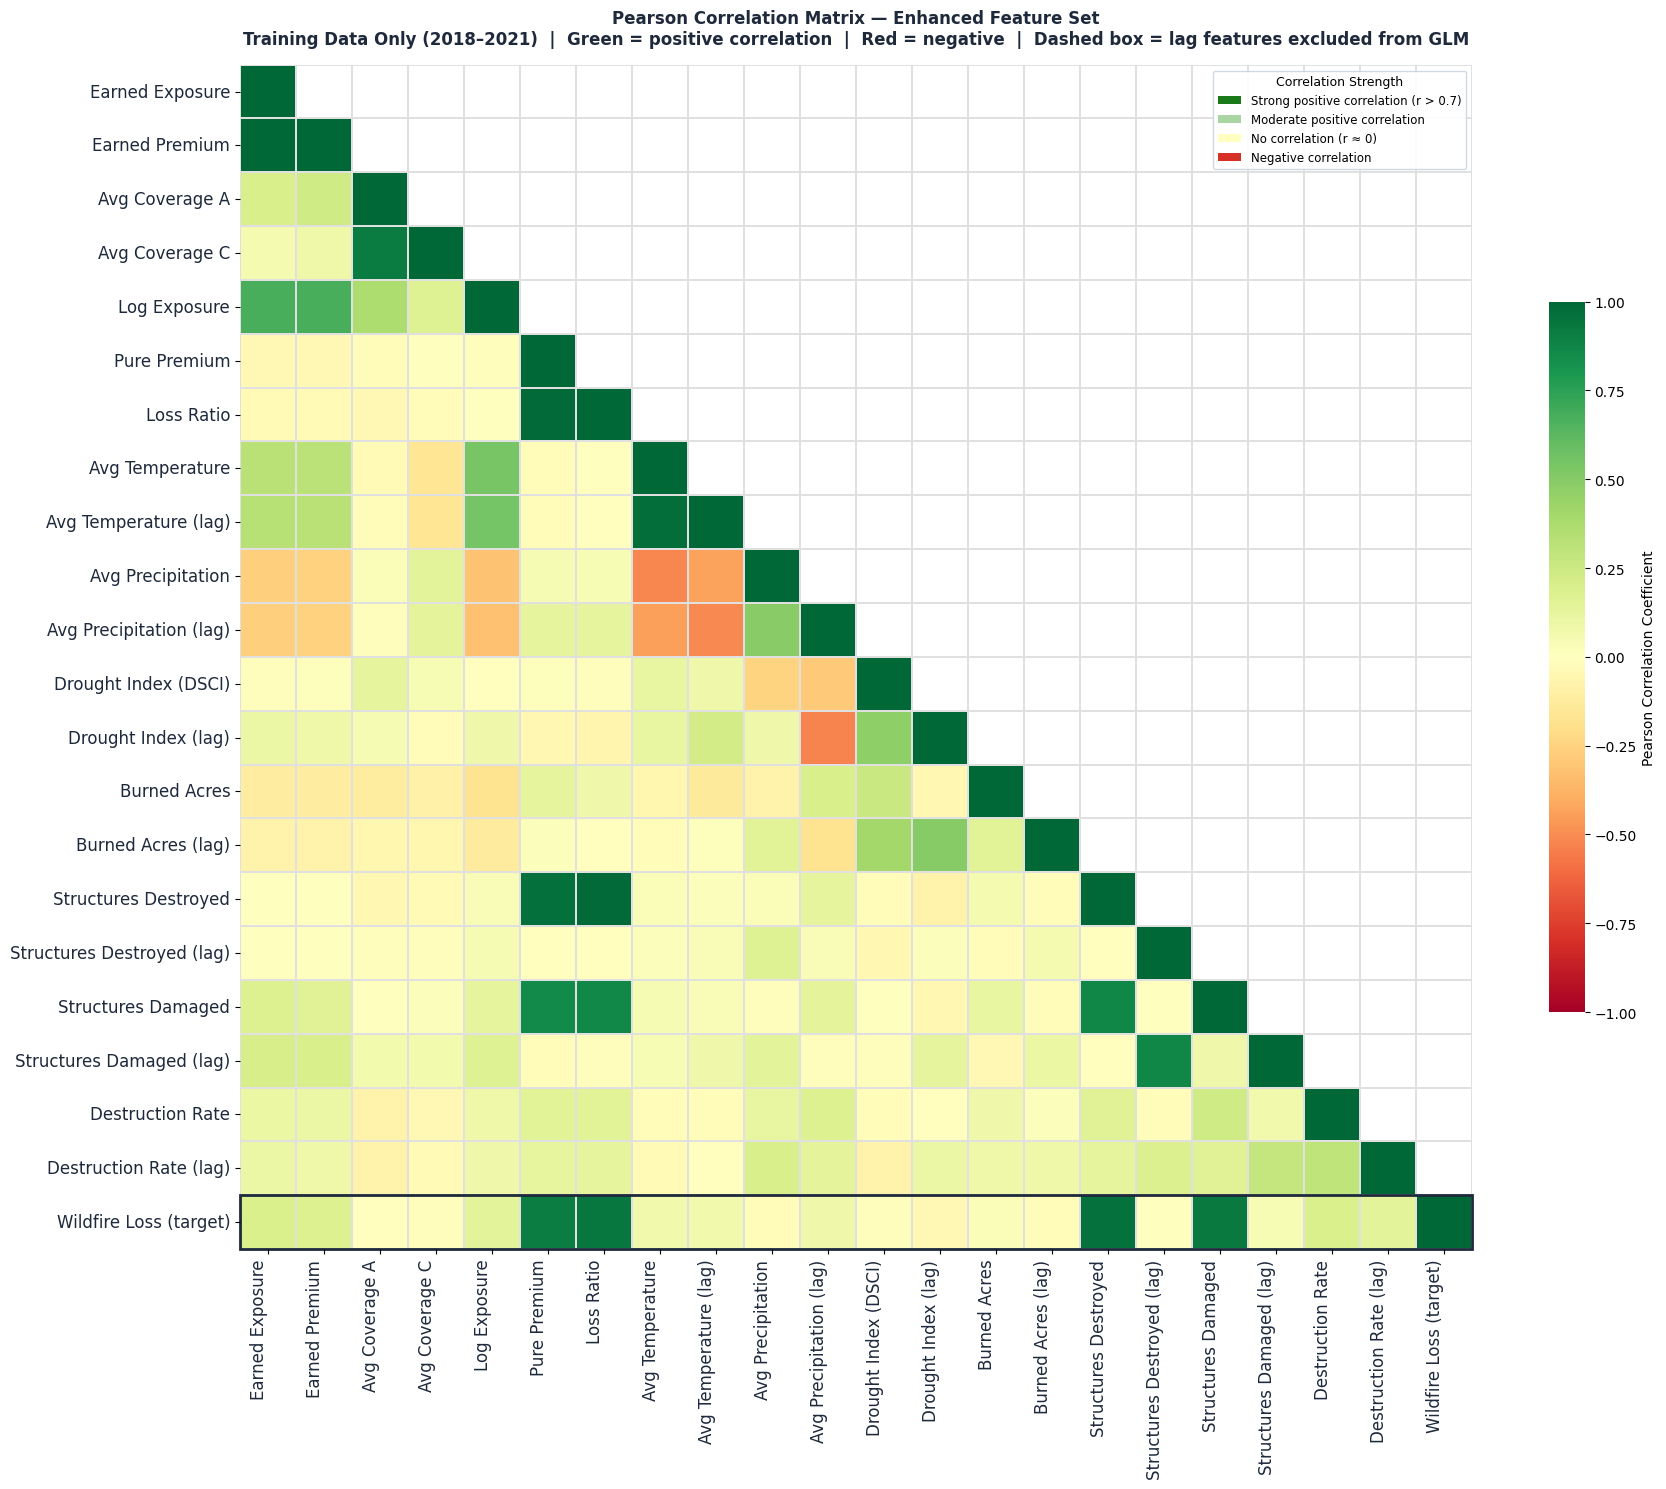


✅ Saved: <PROJECT_ROOT>/Data/../Plots/correlation_heatmap.png

KEY CORRELATION FINDINGS FOR REPORT

Features most correlated with Wildfire Loss:
  Structures Destroyed                |r| = 0.96
  Loss Ratio                          |r| = 0.93
  Structures Damaged                  |r| = 0.93
  Pure Premium                        |r| = 0.91
  Earned Exposure                     |r| = 0.19

Highly correlated pairs (potential multicollinearity):
  Earned Exposure                     Earned Premium                      r=0.99
  Avg Coverage A                      Avg Coverage C                      r=0.92
  Pure Premium                        Loss Ratio                          r=0.99
  Pure Premium                        Structures Destroyed                r=0.96
  Pure Premium                        Structures Damaged                  r=0.86
  Loss Ratio                          Structures Destroyed                r=0.99
  Loss Ratio                          Structures Damaged           

In [46]:
# ============================================================
# CORRELATION HEATMAP — Enhanced Feature Set
# Pearson correlation matrix for feature selection analysis
# Used in Section 3.4 of report
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ── Paths ──────────────────────────────────────────────────────
# Set BASE to the folder that holds the raw data (see README)
BASE       = "./Data"
OUTPUT_DIR = f"{BASE}/../Processed Data"
PLOT_DIR   = f"{BASE}/../Plots"
os.makedirs(PLOT_DIR, exist_ok=True)

TARGET = "Total_Wildfire_Loss"

# ── Load enhanced training data only ──────────────────────────
# Correlation computed on TRAINING data only — no test leakage
enhanced_df = pd.read_csv(f"{OUTPUT_DIR}/master_enhanced.csv")
train       = enhanced_df[enhanced_df["Split"] == "train"].copy()

print(f"Training data shape: {train.shape}")

# ── Feature columns — exclude identifiers and target ──────────
FEATURE_COLS = [
    # Insurance
    "Earned_Exp", "Earned_Prem", "Avg_Cov_A", "Avg_Cov_C",
    "Log_Exposure", "Pure_Premium", "Loss_Ratio",
    # Climate
    "Avg_Temperature", "Lag_Avg_Temperature",
    "Avg_Precipitation", "Lag_Avg_Precipitation",
    # Drought
    "Avg_DSCI", "Lag_Avg_DSCI",
    # Fire
    "Burned_Acres", "Lag_Burned_Acres",
    # Structures
    "Structures_Destroyed", "Lag_Structures_Destroyed",
    "Structures_Damaged", "Lag_Structures_Damaged",
    "Destruction_Rate", "Lag_Destruction_Rate",
    # Target
    "Total_Wildfire_Loss",
]

# Readable labels for heatmap
LABELS = {
    "Earned_Exp":               "Earned Exposure",
    "Earned_Prem":              "Earned Premium",
    "Avg_Cov_A":                "Avg Coverage A",
    "Avg_Cov_C":                "Avg Coverage C",
    "Log_Exposure":             "Log Exposure",
    "Pure_Premium":             "Pure Premium",
    "Loss_Ratio":               "Loss Ratio",
    "Avg_Temperature":          "Avg Temperature",
    "Lag_Avg_Temperature":      "Avg Temperature (lag)",
    "Avg_Precipitation":        "Avg Precipitation",
    "Lag_Avg_Precipitation":    "Avg Precipitation (lag)",
    "Avg_DSCI":                 "Drought Index (DSCI)",
    "Lag_Avg_DSCI":             "Drought Index (lag)",
    "Burned_Acres":             "Burned Acres",
    "Lag_Burned_Acres":         "Burned Acres (lag)",
    "Structures_Destroyed":     "Structures Destroyed",
    "Lag_Structures_Destroyed": "Structures Destroyed (lag)",
    "Structures_Damaged":       "Structures Damaged",
    "Lag_Structures_Damaged":   "Structures Damaged (lag)",
    "Destruction_Rate":         "Destruction Rate",
    "Lag_Destruction_Rate":     "Destruction Rate (lag)",
    "Total_Wildfire_Loss":      "Wildfire Loss (target)",
}

# ── Compute Pearson correlation matrix ────────────────────────
corr_df   = train[FEATURE_COLS].copy()
corr_df   = corr_df.rename(columns=LABELS)
corr_matrix = corr_df.corr(method="pearson")

print("\nTop correlations with target (Total_Wildfire_Loss):")
target_corr = (corr_matrix["Wildfire Loss (target)"]
               .drop("Wildfire Loss (target)")
               .abs()
               .sort_values(ascending=False))
print(target_corr.head(10).to_string())

print("\nHighly correlated feature pairs (|r| > 0.8):")
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        val = corr_matrix.iloc[i, j]
        if abs(val) > 0.8:
            print(f"  {corr_matrix.columns[i]:<35} "
                  f"{corr_matrix.columns[j]:<35} r={val:.2f}")

# ── Feature selection mapping ─────────────────────────────────
# Color coding for axis labels:
#   Blue   (#2563EB) = selected in ALL 3 models
#   Orange (#EA580C) = GLM + RF only (structure damage —
#                      excluded from XGBoost)
#   Green  (#16A34A) = RF + XGBoost only (lag features —
#                      excluded from GLM due to multicollinearity)
#   Black  (#1E293B) = target variable

ALL_THREE = [
    "Earned Exposure", "Earned Premium", "Avg Coverage A",
    "Avg Coverage C", "Log Exposure", "Pure Premium",
    "Loss Ratio", "Avg Temperature", "Avg Precipitation",
    "Drought Index (DSCI)", "Burned Acres",
]

GLM_RF_ONLY = [
    "Structures Destroyed", "Structures Damaged",
    "Destruction Rate",
]

RF_XGB_ONLY = [
    "Avg Temperature (lag)", "Avg Precipitation (lag)",
    "Drought Index (lag)", "Burned Acres (lag)",
    "Structures Destroyed (lag)", "Structures Damaged (lag)",
    "Destruction Rate (lag)",
]

TARGET_LABEL = ["Wildfire Loss (target)"]

def get_label_color(label):
    if label in ALL_THREE:
        return "#2563EB"   # blue
    elif label in GLM_RF_ONLY:
        return "#EA580C"   # orange
    elif label in RF_XGB_ONLY:
        return "#16A34A"   # green
    elif label in TARGET_LABEL:
        return "#1E293B"   # black
    else:
        return "#6B7280"   # gray fallback

# ── Plot simplified heatmap — collinearity focus ──────────────
# No numbers, no model selection colors, just correlation colors
# Two groups visually separated: current-year vs lag features
fig, ax = plt.subplots(figsize=(18, 15))
fig.patch.set_facecolor("white")

# Mask upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix,
    mask=mask,
    ax=ax,
    cmap='RdYlGn',
    vmin=-1, vmax=1, center=0,
    annot=False,          # no numbers inside boxes
    linewidths=0.3,
    linecolor="#e0e0e0",
    cbar_kws={
        "shrink": 0.6,
        "label": "Pearson Correlation Coefficient",
        "orientation": "vertical"
    }
)

ax.set_facecolor("white")

# Simple axis labels — all same color, no model selection coding
ax.set_xticklabels(ax.get_xticklabels(),
                   rotation=90, ha="right",
                   fontsize=12, color="#1E293B")
ax.set_yticklabels(ax.get_yticklabels(),
                   rotation=0,
                   fontsize=12, color="#1E293B")

# Highlight lag feature rows/columns with a light background
# to draw attention to the collinearity block
lag_labels = [
    "Avg Temperature (lag)", "Avg Precipitation (lag)",
    "Drought Index (lag)", "Burned Acres (lag)",
    "Structures Destroyed (lag)", "Structures Damaged (lag)",
    "Destruction Rate (lag)",
]
all_labels = list(corr_matrix.columns)

# Draw subtle box around lag feature block
#lag_indices = [all_labels.index(l) for l in lag_labels


#if l in all_labels]
#if lag_indices:
#    min_i = min(lag_indices)
#    max_i = max(lag_indices)
#    n_lag = max_i - min_i + 1
#    # Box around lag rows
#    ax.add_patch(plt.Rectangle(
#        (0, min_i), len(all_labels), n_lag,
#        fill=False, edgecolor="#1F3864",
#        linewidth=2, clip_on=False,
#        linestyle="--"))
#    ax.text(23, min_i + n_lag/2,
#            "Lag\nFeatures",
#            ha="right", va="center",
#            fontsize=8, color="#1F3864",
#            fontweight="bold",
#            transform=ax.transData)

# Highlight target row
n = len(corr_matrix)
ax.add_patch(plt.Rectangle(
    (0, n-1), n, 1,
    fill=False, edgecolor="#1E293B",
    linewidth=2, clip_on=False))

# Simple legend — just explain the colors
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#1a7a1a",
          label="Strong positive correlation (r > 0.7)"),
    Patch(facecolor="#a8d5a2",
          label="Moderate positive correlation"),
    Patch(facecolor="#ffffbf",
          label="No correlation (r ≈ 0)"),
    Patch(facecolor="#d73027",
          label="Negative correlation"),
]
ax.legend(
    handles=legend_elements,
    loc="upper right",
    fontsize=8.5,
    framealpha=0.92,
    edgecolor="#CBD5E1",
    title="Correlation Strength",
    title_fontsize=9,
    bbox_to_anchor=(1.0, 1.0)
)

ax.set_title(
    "Pearson Correlation Matrix — Enhanced Feature Set\n"
    "Training Data Only (2018–2021)  |  "
    "Green = positive correlation  |  Red = negative  |  "
    "Dashed box = lag features excluded from GLM",
    fontsize=12, fontweight="bold",
    color="#1E293B", pad=15)

plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/correlation_heatmap.png",
            dpi=150, bbox_inches="tight",
            facecolor="white")
plt.show()
print(f"\n✅ Saved: {PLOT_DIR}/correlation_heatmap.png")

# ── Key findings summary ───────────────────────────────────────
print("\n" + "=" * 65)
print("KEY CORRELATION FINDINGS FOR REPORT")
print("=" * 65)

print("\nFeatures most correlated with Wildfire Loss:")
for feat, val in target_corr.head(5).items():
    print(f"  {feat:<35} |r| = {val:.2f}")

print("\nHighly correlated pairs (potential multicollinearity):")
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        val = corr_matrix.iloc[i, j]
        if abs(val) > 0.7 and \
           "target" not in corr_matrix.columns[i].lower() and \
           "target" not in corr_matrix.columns[j].lower():
            print(f"  {corr_matrix.columns[i]:<35} "
                  f"{corr_matrix.columns[j]:<35} r={val:.2f}")

